Условие задачи

Вы работаете в онлайн-школе аналитиком. Вы знаете, что все клиенты школы были разделены на сегменты A/B/C/D на основе экспертной оценки. Это сделано, чтобы обеспечить высокий уровень клиентского сервиса.

Сейчас вы хотите оказывать клиентскую поддержку различным группам пользователей в зависимости от их возраста и наличия высшего образования. Ваша задача оценить, подходит ли текущая сегментация пользователей для новых задач или ее необходимо переделать.

Формальное описание задачи:

Оценить, влияет ли возраст и уровень образования на сегмент пользователя.

Алгоритм решения:

    Загрузите данные из файла формата CSV.
    Проведите предварительный анализ данных: изучите структуру набора данных, определите переменные, которые необходимо будет исследовать. Удалите наблюдения, в которых необходимые переменные пропущены.
    Проведите One-way ANOVA и Two-way ANOVA.
    Проверьте ограничения на применимость методов: нормальность и гомоскедастичность. Независимость наблюдений гарантируется.
    Проведите апостериорный анализ при наличии статистически значимых результатов.
    Сделайте выводы о влиянии уровня образования и возраста на сегмент пользователя.


In [3]:
import pandas as pd
import seaborn as sns

from scipy import stats

# anova model from formula
from statsmodels.formula.api import ols
# anova table from ols model
from statsmodels.stats.anova import anova_lm
# for qqplot
import statsmodels.api as sm
# tukey test
from statsmodels.stats.multicomp import pairwise_tukeyhsd



In [4]:
# загружаем данные
data = pd.read_csv('Customer Segmentation.csv', index_col=0)
data.head()

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10695 entries, 0 to 10694
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               10695 non-null  int64  
 1   Gender           10695 non-null  object 
 2   Ever_Married     10505 non-null  object 
 3   Age              10695 non-null  int64  
 4   Graduated        10593 non-null  object 
 5   Profession       10533 non-null  object 
 6   Work_Experience  9597 non-null   float64
 7   Spending_Score   10695 non-null  object 
 8   Family_Size      10247 non-null  float64
 9   Var_1            10587 non-null  object 
 10  Segmentation     10695 non-null  object 
dtypes: float64(2), int64(2), object(7)
memory usage: 1002.7+ KB


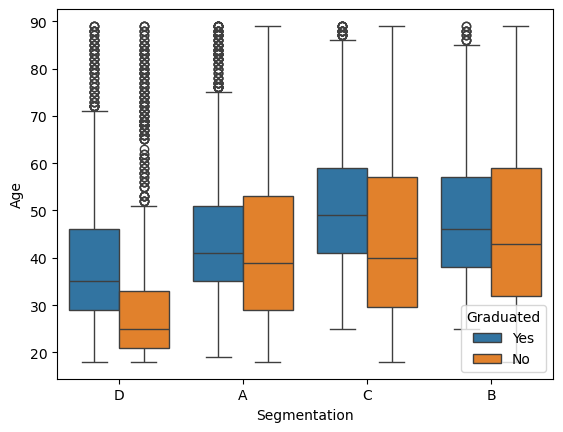

In [5]:
# удаляем наблюдения с пропущенными значениями
data = data[data.Graduated.isna() != True]

sns.boxplot(data=data, x='Segmentation', y='Age', hue='Graduated');


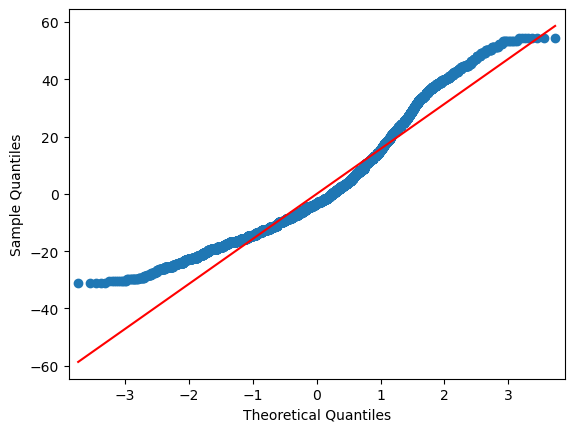

In [6]:
#one-way anova
one_way = ols('Age ~ Segmentation', data).fit()
anova_lm(one_way)

#qq-plot, проверяем нормальность остатков
sm.qqplot(one_way.resid, line='s');

In [7]:
#разделяем данные по сегментам, чтобы провести тест Левена
groups = []
for group_id, group in data.groupby(['Segmentation']):
    groups.append(group.Age)

#тест Левена
stats.bartlett(*groups)

BartlettResult(statistic=np.float64(45.56531070451098), pvalue=np.float64(7.016351793679876e-10))

In [ ]:
#апостериорный анализ
print(pairwise_tukeyhsd(endog=data.Age, groups=data.Segmentation, alpha=0.05))

In [ ]:
#two-way anova
two_way = ols('Age ~ Segmentation + Graduated + Segmentation:Graduated', data).fit()
anova_lm(two_way)

#qq-plot, проверяем нормальность остатков
sm.qqplot(two_way.resid, line='s');

In [ ]:
#разделяем данные по сегментам и образованию, чтобы провести тест Левена
groups = []
for group_id, group in data.groupby(['Segmentation', 'Graduated']):
    groups.append(group.Age)

#тест Левена
stats.bartlett(*groups)

In [ ]:
#апостериорный анализ
data['combination'] = data.Segmentation + '/' + data.Graduated
print(pairwise_tukeyhsd(endog=data.Age.astype('float'), groups=data.combination, alpha=0.05))

Из проведенного анализа данных можно сделать следующие выводы:

    1. Возраст пользователя имеет статистическую значимость при разделении на сегменты. Также возраст пользователя имеет статистическую значимость при разделении сегментов на уровни образования в них.
    2. Для нового типа клиентской поддержки нет необходимости менять текущую сегментацию пользователей, достаточно будет только подразделить уже существующие сегменты по уровню образования.